In [1]:
import os

print("Current folder:", os.getcwd())

print("\nModel files:")
for filename in os.listdir("."):
    if filename.endswith((".pth", ".pt")):
        print(filename)

print("\nModel in memory:", "model" in globals())

Current folder: c:\Users\pc\Documents\computervision ass1

Model files:

Model in memory: False


In [2]:
import os

classes = ["book", "bottle", "clock", "keyboard"]
splits = ["train", "validation", "test"]

for split in splits:
    print(f"\n{split.upper()}")

    for class_name in classes:
        folder = os.path.join("dataset", split, class_name)

        if os.path.exists(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".webp")
                )
            ])

            print(f"{class_name}: {count}")
        else:
            print(f"{class_name}: FOLDER NOT FOUND")


TRAIN
book: 70
bottle: 70
clock: 70
keyboard: 70

VALIDATION
book: 15
bottle: 15
clock: 15
keyboard: 15

TEST
book: 15
bottle: 15
clock: 15
keyboard: 15


In [3]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.8, 1.0)
    ),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.ImageFolder(
    "dataset/train",
    transform=train_transform
)

validation_dataset = datasets.ImageFolder(
    "dataset/validation",
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    "dataset/test",
    transform=val_test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

classes = train_dataset.classes

print("Classes:", classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

Classes: ['book', 'bottle', 'clock', 'keyboard']
Training images: 280
Validation images: 60
Test images: 60


In [4]:
import torch
import torch.nn as nn
from torchvision import models

# Загружаем ResNet18 с предобученными весами
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Меняем последний слой для наших 4 классов
model.fc = nn.Linear(
    model.fc.in_features,
    len(classes)
)

# Выбираем устройство
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Device:", device)
print("Output classes:", model.fc.out_features)
print("Model:", type(model).__name__)

Device: cpu
Output classes: 4
Model: ResNet


In [5]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", type(criterion).__name__)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001


In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Обнуляем старые градиенты
        optimizer.zero_grad()

        # Forward pass: получаем предсказания
        outputs = model(images)

        # Вычисляем ошибку
        loss = criterion(outputs, labels)

        # Backward pass: вычисляем градиенты
        loss.backward()

        # Обновляем веса модели
        optimizer.step()

        # Собираем статистику
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training function is ready!")

Training function is ready!


In [7]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    # Отключаем вычисление градиентов
    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Получаем предсказания
            outputs = model(images)

            # Вычисляем ошибку
            loss = criterion(outputs, labels)

            # Определяем предсказанные классы
            predictions = outputs.argmax(dim=1)

            # Собираем статистику
            running_loss += loss.item() * images.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_accuracy = correct / total

    return val_loss, val_accuracy


print("Validation function is ready!")

Validation function is ready!


In [8]:
import torch
import os

num_epochs = 15

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_accuracy = -1.0

os.makedirs("models", exist_ok=True)

for epoch in range(num_epochs):

    # 1. Обучение
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # 2. Валидация
    val_loss, val_accuracy = validate(
        model,
        validation_loader,
        criterion,
        device
    )

    # 3. Сохраняем историю для графиков
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # 4. Сохраняем лучшую модель
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "models/resnet18_household.pth"
        )

        print("  Best model saved!")

    # 5. Выводим результаты эпохи
    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

print("\nTraining completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
print(
    "Model file exists:",
    os.path.exists("models/resnet18_household.pth")
)

  Best model saved!
Epoch 1/15 | Train Loss: 0.7524 | Train Acc: 0.7286 | Val Loss: 0.2139 | Val Acc: 0.9833
Epoch 2/15 | Train Loss: 0.1148 | Train Acc: 0.9857 | Val Loss: 0.0863 | Val Acc: 0.9833
Epoch 3/15 | Train Loss: 0.0323 | Train Acc: 1.0000 | Val Loss: 0.0551 | Val Acc: 0.9833
  Best model saved!
Epoch 4/15 | Train Loss: 0.0197 | Train Acc: 1.0000 | Val Loss: 0.0436 | Val Acc: 1.0000
Epoch 5/15 | Train Loss: 0.0118 | Train Acc: 1.0000 | Val Loss: 0.0389 | Val Acc: 1.0000
Epoch 6/15 | Train Loss: 0.0084 | Train Acc: 1.0000 | Val Loss: 0.0357 | Val Acc: 1.0000
Epoch 7/15 | Train Loss: 0.0116 | Train Acc: 1.0000 | Val Loss: 0.0352 | Val Acc: 1.0000
Epoch 8/15 | Train Loss: 0.0108 | Train Acc: 0.9964 | Val Loss: 0.0269 | Val Acc: 1.0000
Epoch 9/15 | Train Loss: 0.0067 | Train Acc: 1.0000 | Val Loss: 0.0203 | Val Acc: 1.0000
Epoch 10/15 | Train Loss: 0.0029 | Train Acc: 1.0000 | Val Loss: 0.0204 | Val Acc: 1.0000
Epoch 11/15 | Train Loss: 0.0054 | Train Acc: 1.0000 | Val Loss: 0.02

In [9]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Загружаем сохранённые веса
model.load_state_dict(
    torch.load(
        "models/resnet18_household.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# 2. Собираем предсказания
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

# 3. Вычисляем метрики
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

recall = recall_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

print("ResNet18 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

ResNet18 Test Results
---------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

        book       1.00      1.00      1.00        15
      bottle       1.00      1.00      1.00        15
       clock       1.00      1.00      1.00        15
    keyboard       1.00      1.00      1.00        15

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



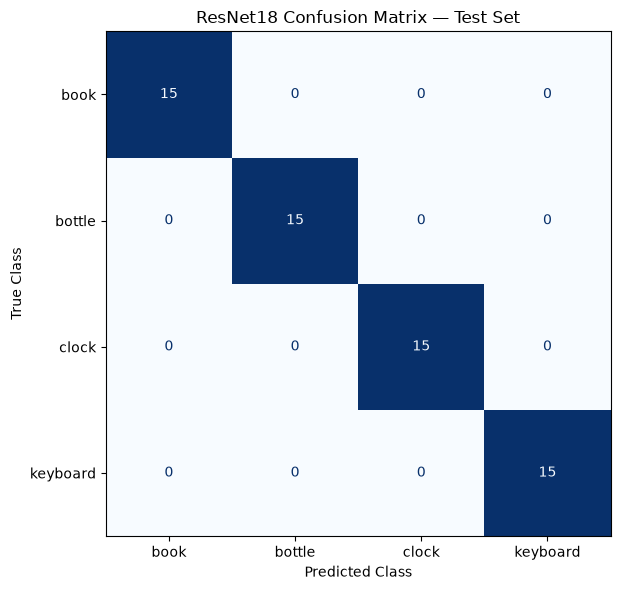

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("ResNet18 Confusion Matrix — Test Set")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()

# Сохраняем график для отчёта
plt.savefig(
    "resnet18_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

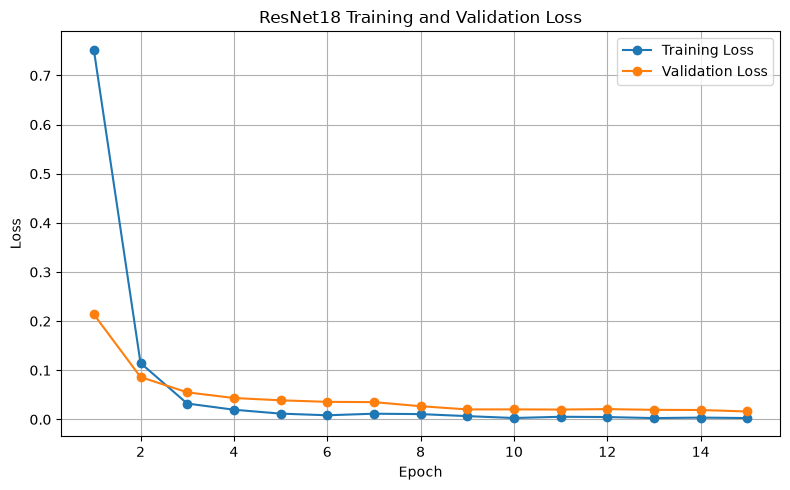

In [11]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet18 Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "resnet18_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import transformers

print("Transformers version:", transformers.__version__)
print("DINOv2 dependencies installed successfully!")

c:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers version: 5.22.2
DINOv2 dependencies installed successfully!


In [13]:
import torch
from transformers import AutoImageProcessor, AutoModel

model_name = "facebook/dinov2-small"

# Загружаем preprocessing DINOv2
dino_processor = AutoImageProcessor.from_pretrained(
    model_name
)

# Загружаем предобученную DINOv2
dino_model = AutoModel.from_pretrained(
    model_name
)

# Используем CPU
dino_device = torch.device("cpu")
dino_model = dino_model.to(dino_device)

# Режим inference
dino_model.eval()

print("DINOv2 loaded successfully!")
print("Model:", model_name)
print("Device:", dino_device)
print("Hidden size:", dino_model.config.hidden_size)

c:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\models--facebook--dinov2-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_downloa

DINOv2 loaded successfully!
Model: facebook/dinov2-small
Device: cpu
Hidden size: 384


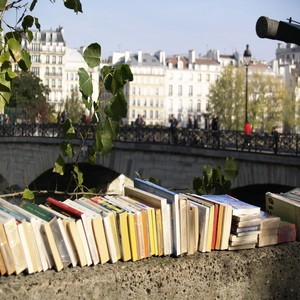

Image: 00300007.jpg
Embedding shape: torch.Size([1, 384])
First 10 features:
tensor([ 0.6909, -0.6546, -0.6630,  0.7575,  3.1975,  0.0478,  1.1892,  0.3756,
         0.3272, -1.9564])


In [14]:
from PIL import Image
import os
import torch

# Берём одну фотографию книги
image_folder = "dataset/train/book"

image_name = next(
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
)

image_path = os.path.join(image_folder, image_name)

image = Image.open(image_path).convert("RGB")

# Показываем изображение
display(image)

# Подготавливаем изображение для DINOv2
inputs = dino_processor(
    images=image,
    return_tensors="pt"
)

inputs = {
    key: value.to(dino_device)
    for key, value in inputs.items()
}

# Получаем признаки
with torch.no_grad():
    outputs = dino_model(**inputs)

    # CLS token — общее представление изображения
    embedding = outputs.last_hidden_state[:, 0, :]

print("Image:", image_name)
print("Embedding shape:", embedding.shape)
print("First 10 features:")
print(embedding[0, :10])

In [15]:
import os
import numpy as np
import torch
from PIL import Image

def extract_dino_features(folder, batch_size=8):
    features = []
    labels = []

    image_paths = []
    image_labels = []

    # Собираем пути к фотографиям
    for label, class_name in enumerate(classes):
        class_folder = os.path.join(folder, class_name)

        for filename in sorted(os.listdir(class_folder)):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                image_paths.append(
                    os.path.join(class_folder, filename)
                )
                image_labels.append(label)

    dino_model.eval()

    # Обрабатываем изображения по batches
    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]

        images = [
            Image.open(path).convert("RGB")
            for path in batch_paths
        ]

        inputs = dino_processor(
            images=images,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(dino_device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            outputs = dino_model(**inputs)

            embeddings = outputs.last_hidden_state[:, 0, :]

        features.append(embeddings.cpu().numpy())

        labels.extend(
            image_labels[start:start + batch_size]
        )

    return np.vstack(features), np.array(labels)


# Извлекаем признаки для всех наборов
X_train_dino, y_train_dino = extract_dino_features(
    "dataset/train"
)

print("Train:", X_train_dino.shape, y_train_dino.shape)

X_val_dino, y_val_dino = extract_dino_features(
    "dataset/validation"
)

print("Validation:", X_val_dino.shape, y_val_dino.shape)

X_test_dino, y_test_dino = extract_dino_features(
    "dataset/test"
)

print("Test:", X_test_dino.shape, y_test_dino.shape)

Train: (280, 384) (280,)
Validation: (60, 384) (60,)
Test: (60, 384) (60,)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# Создаём классификатор
dino_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        C=1.0
    )
)

# Обучаем только на TRAIN
dino_classifier.fit(
    X_train_dino,
    y_train_dino
)

# Проверяем на VALIDATION
y_val_pred_dino = dino_classifier.predict(
    X_val_dino
)

val_accuracy_dino = accuracy_score(
    y_val_dino,
    y_val_pred_dino
)

print("DINOv2 + Logistic Regression")
print("----------------------------")
print(f"Validation Accuracy: {val_accuracy_dino:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val_dino,
        y_val_pred_dino,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

DINOv2 + Logistic Regression
----------------------------
Validation Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

        book       1.00      1.00      1.00        15
      bottle       1.00      1.00      1.00        15
       clock       1.00      1.00      1.00        15
    keyboard       1.00      1.00      1.00        15

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Предсказания DINOv2 + Logistic Regression
y_test_pred_dino = dino_classifier.predict(
    X_test_dino
)

# Вычисляем метрики
dino_accuracy = accuracy_score(
    y_test_dino,
    y_test_pred_dino
)

dino_precision = precision_score(
    y_test_dino,
    y_test_pred_dino,
    average="weighted",
    zero_division=0
)

dino_recall = recall_score(
    y_test_dino,
    y_test_pred_dino,
    average="weighted",
    zero_division=0
)

dino_f1 = f1_score(
    y_test_dino,
    y_test_pred_dino,
    average="weighted",
    zero_division=0
)

print("DINOv2 Test Results")
print("-------------------")
print(f"Accuracy : {dino_accuracy:.4f}")
print(f"Precision: {dino_precision:.4f}")
print(f"Recall   : {dino_recall:.4f}")
print(f"F1-score : {dino_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_dino,
        y_test_pred_dino,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

DINOv2 Test Results
-------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

        book       1.00      1.00      1.00        15
      bottle       1.00      1.00      1.00        15
       clock       1.00      1.00      1.00        15
    keyboard       1.00      1.00      1.00        15

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



In [18]:
import os
import numpy as np
from PIL import Image
import torch

folder = "new_test"

results = []

for filename in sorted(os.listdir(folder)):

    if not filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    ):
        continue

    image_path = os.path.join(folder, filename)
    image = Image.open(image_path).convert("RGB")

    # Preprocessing для DINOv2
    inputs = dino_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(dino_device)
        for key, value in inputs.items()
    }

    # Извлекаем 384 признака
    with torch.no_grad():
        outputs = dino_model(**inputs)
        embedding = outputs.last_hidden_state[:, 0, :]

    # Передаём признаки классификатору
    features = embedding.cpu().numpy()

    prediction = dino_classifier.predict(features)[0]

    probabilities = dino_classifier.predict_proba(features)[0]
    confidence = probabilities.max() * 100

    predicted_class = classes[prediction]

    results.append((filename, predicted_class, confidence))

    print(
        f"{filename} → {predicted_class} "
        f"({confidence:.2f}%)"
    )

# Accuracy, если все изображения в new_test — книги
if results:
    correct = sum(
        predicted_class == "book"
        for _, predicted_class, _ in results
    )

    accuracy_new = correct / len(results)

    print("\nNew Images Accuracy:", f"{accuracy_new:.2%}")
    print("Correct:", correct, "/", len(results))

2w3.png → book (99.93%)
3wfds.png → book (99.45%)
4.png → book (99.21%)
5.png → book (95.43%)
book_noun_001_01679.jpg → book (96.32%)
image.png → book (99.14%)
image1.png → book (99.46%)
image2.png → book (99.51%)
image3.png → book (99.60%)
istockphoto-157482029-612x612.jpg → book (99.65%)

New Images Accuracy: 100.00%
Correct: 10 / 10


In [19]:
import os
import torch
from PIL import Image

folder = "new_test"

# Загружаем сохранённую ResNet18
model.load_state_dict(
    torch.load(
        "models/resnet18_household.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

resnet_results = []

for filename in sorted(os.listdir(folder)):

    if not filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    ):
        continue

    image_path = os.path.join(folder, filename)

    image = Image.open(image_path).convert("RGB")

    # Используем preprocessing ResNet18
    image_tensor = val_test_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)
        confidence, prediction = probabilities.max(dim=1)

    predicted_class = classes[prediction.item()]
    confidence_value = confidence.item() * 100

    resnet_results.append(
        (filename, predicted_class, confidence_value)
    )

    print(
        f"{filename} → {predicted_class} "
        f"({confidence_value:.2f}%)"
    )

# Считаем accuracy, если ВСЕ фотографии — книги
if resnet_results:
    correct = sum(
        predicted_class == "book"
        for _, predicted_class, _ in resnet_results
    )

    accuracy_resnet_new = correct / len(resnet_results)

    print("\nResNet18 New Images Accuracy:",
          f"{accuracy_resnet_new:.2%}")
    print("Correct:", correct, "/", len(resnet_results))

2w3.png → book (99.96%)
3wfds.png → book (54.00%)
4.png → bottle (54.37%)
5.png → book (72.53%)
book_noun_001_01679.jpg → clock (54.64%)
image.png → book (91.36%)
image1.png → book (55.82%)
image2.png → bottle (71.79%)
image3.png → book (76.53%)
istockphoto-157482029-612x612.jpg → book (95.26%)

ResNet18 New Images Accuracy: 70.00%
Correct: 7 / 10


In [21]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    dino_classifier,
    "models/dinov2_classifier.pkl"
)

print(
    "Classifier saved:",
    os.path.exists("models/dinov2_classifier.pkl")
)

print(
    "Classes:",
    classes
)

Classifier saved: True
Classes: ['book', 'bottle', 'clock', 'keyboard']


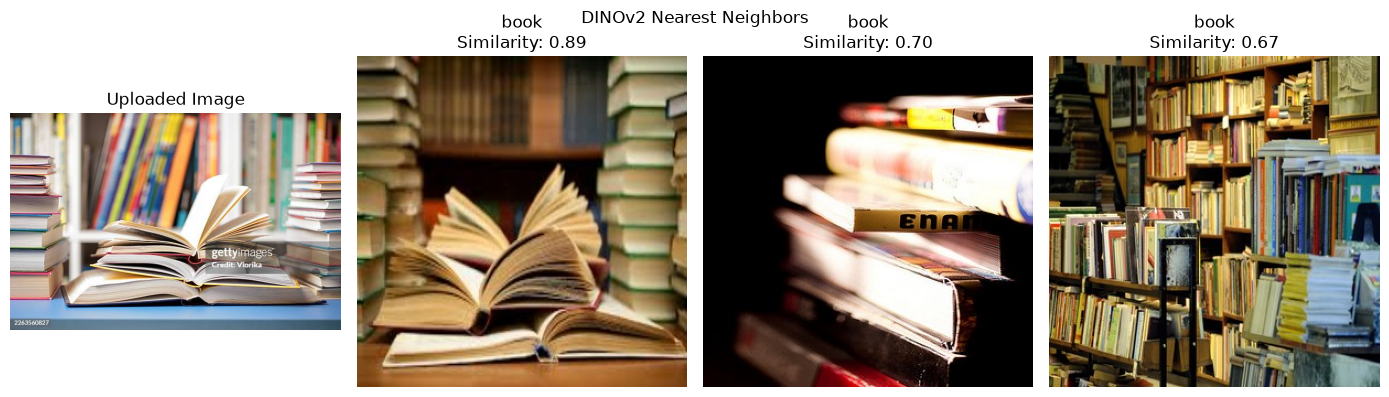

In [22]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from PIL import Image
import matplotlib.pyplot as plt
import os

# Выбираем первую новую фотографию
new_folder = "new_test"

new_image_name = sorted([
    f for f in os.listdir(new_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])[0]

new_image_path = os.path.join(new_folder, new_image_name)

image = Image.open(new_image_path).convert("RGB")

# Получаем DINOv2-признаки новой фотографии
inputs = dino_processor(
    images=image,
    return_tensors="pt"
).to(dino_device)

with torch.no_grad():
    outputs = dino_model(**inputs)
    new_embedding = outputs.last_hidden_state[:, 0, :].cpu().numpy()

# Сравниваем с тренировочными изображениями
similarities = cosine_similarity(
    new_embedding,
    X_train_dino
)[0]

# Находим индексы трёх самых похожих
top_indices = np.argsort(similarities)[-3:][::-1]

# Восстанавливаем порядок путей из шага 15
train_paths = []

for class_name in classes:
    class_folder = os.path.join("dataset/train", class_name)

    for filename in sorted(os.listdir(class_folder)):
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        ):
            train_paths.append(
                os.path.join(class_folder, filename)
            )

# Показываем результат
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(image)
axes[0].set_title("Uploaded Image")
axes[0].axis("off")

for i, idx in enumerate(top_indices):
    similar_image = Image.open(train_paths[idx]).convert("RGB")

    axes[i + 1].imshow(similar_image)
    axes[i + 1].set_title(
        f"{classes[y_train_dino[idx]]}\n"
        f"Similarity: {similarities[idx]:.2f}"
    )
    axes[i + 1].axis("off")

plt.suptitle("DINOv2 Nearest Neighbors")
plt.tight_layout()

plt.savefig(
    "dinov2_nearest_neighbors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Variant A: без StandardScaler
dino_no_scaler = LogisticRegression(
    max_iter=2000,
    C=1.0
)

dino_no_scaler.fit(
    X_train_dino,
    y_train_dino
)

pred_no_scaler = dino_no_scaler.predict(
    X_val_dino
)

accuracy_no_scaler = accuracy_score(
    y_val_dino,
    pred_no_scaler
)

f1_no_scaler = f1_score(
    y_val_dino,
    pred_no_scaler,
    average="weighted"
)

# Variant B: с StandardScaler
pred_with_scaler = dino_classifier.predict(
    X_val_dino
)

accuracy_with_scaler = accuracy_score(
    y_val_dino,
    pred_with_scaler
)

f1_with_scaler = f1_score(
    y_val_dino,
    pred_with_scaler,
    average="weighted"
)

print("ABLATION EXPERIMENT")
print("----------------------------")

print("Without StandardScaler")
print(f"Accuracy: {accuracy_no_scaler:.4f}")
print(f"F1-score: {f1_no_scaler:.4f}")

print("\nWith StandardScaler")
print(f"Accuracy: {accuracy_with_scaler:.4f}")
print(f"F1-score: {f1_with_scaler:.4f}")

ABLATION EXPERIMENT
----------------------------
Without StandardScaler
Accuracy: 1.0000
F1-score: 1.0000

With StandardScaler
Accuracy: 1.0000
F1-score: 1.0000


In [24]:
import time
import numpy as np
from PIL import Image
import torch

# Одна тестовая фотография
image = Image.open(
    test_dataset.samples[0][0]
).convert("RGB")

# -------------------------
# ResNet18 latency
# -------------------------

model.eval()

resnet_times = []

for _ in range(10):
    start = time.perf_counter()

    image_tensor = val_test_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        prediction = output.argmax(dim=1)

    elapsed = time.perf_counter() - start
    resnet_times.append(elapsed * 1000)

# -------------------------
# DINOv2 latency
# -------------------------

dino_model.eval()

dino_times = []

for _ in range(10):
    start = time.perf_counter()

    inputs = dino_processor(
        images=image,
        return_tensors="pt"
    ).to(dino_device)

    with torch.no_grad():
        outputs = dino_model(**inputs)
        embedding = outputs.last_hidden_state[:, 0, :]

    features = embedding.cpu().numpy()
    prediction = dino_classifier.predict(features)

    elapsed = time.perf_counter() - start
    dino_times.append(elapsed * 1000)

print("INFERENCE LATENCY")
print("---------------------------")
print("Device:", device)
print(f"ResNet18: {np.mean(resnet_times):.2f} ms")
print(f"DINOv2:   {np.mean(dino_times):.2f} ms")

INFERENCE LATENCY
---------------------------
Device: cpu
ResNet18: 45.95 ms
DINOv2:   164.20 ms
